# Supplemental Analyses

In [1]:
import Pkg
Pkg.activate("MusicalExpectation")
Pkg.add("Gen")
Pkg.add("Plots")
Pkg.add(["CSV", "DataFrames"])
Pkg.add("Distributions")
Pkg.add("HypothesisTests")
Pkg.add("GLM")
Pkg.add("ProgressBars")
Pkg.add("JSON")

include("utils/draw.jl")
include("utils/scale.jl")
include("utils/force.jl")
include("utils/data.jl")

using Gen
using Plots
using CSV
using Dates
using ProgressBars
using DataFrames
using Distributions
using Statistics
using HypothesisTests
using Random
using GLM
using JSON
using .ScaleUtils
using .ForceUtils
using .DataUtils
;

  Activating project at `~/Documents/GitHub/PMFM_Rhythm/MusicalExpectation`
    Updating registry at `~/.julia/registries/General.toml`
   Resolving package versions...
   Installed Xorg_libpciaccess_jll ─ v0.18.1+0
   Installed libdrm_jll ──────────── v2.4.125+1
   Installed libva_jll ───────────── v2.23.0+0
     Project No packages added to or removed from `~/Documents/GitHub/PMFM_Rhythm/MusicalExpectation/Project.toml`
    Updating `~/Documents/GitHub/PMFM_Rhythm/MusicalExpectation/Manifest.toml`
  [a65dc6b1] + Xorg_libpciaccess_jll v0.18.1+0
  [8e53e030] + libdrm_jll v2.4.125+1
  [9a156e7d] + libva_jll v2.23.0+0
Precompiling packages...
    549.6 ms  ✓ Xorg_libpciaccess_jll
    387.9 ms  ✓ libdrm_jll
    421.0 ms  ✓ libva_jll
  3 dependencies successfully precompiled in 2 seconds. 274 already precompiled.
   Resolving package versions...
     Project No packages added to or removed from `~/Documents/GitHub/PMFM_Rhythm/MusicalExpectation/Project.toml`
    Manifest No packages added 

In [2]:
# Creates some major scales to draw from later on
C_NOTE = 60

C = create_major_scale(C_NOTE)
G = create_major_scale(55)  
D = create_major_scale(62)  
A = create_major_scale(57)  
E = create_major_scale(64)  
B = create_major_scale(59)  
F♯ = create_major_scale(66)
G♭ = create_major_scale(66)
D♭ = create_major_scale(61)
A♭ = create_major_scale(56)
E♭ = create_major_scale(63)
B♭ = create_major_scale(58)
F = create_major_scale(65)

major_scales = [C, G, D, A, E, B, F♯, G♭, D♭, A♭, E♭, B♭, F]
;

In [3]:
# Initialize params
σ_gravity = 0.2
σ_magnetism = 1.5
σ_inertia = 0.01
σ_note = 0.025
w_g, w_m, w_i = 1.2, 0.1, 4.0
α = 0.1
σ_step_base  = 0.6
σ_pitch_obs  = 0.7
γ = 0.25
;

In [4]:
"""
Single step transition in the melody model. Samples duration Δt and next note based on gravity, magnetism, and inertia forces.
"""
@gen function melody_kernel(k::Int, state::Tuple{Note,Note}, key::MusicalScale, measure_length::Int=8)
    # Initial scaling parameters
    prev_note, curr_note = state

    # Rhythmic transition
    Δt ~ categorical(fill(1.0 / measure_length, measure_length))

    # Force calculations
    gravity   = @trace(normal(calculate_gravity(curr_note, key), σ_gravity), :gravity)
    magnetism = @trace(normal(calculate_magnetism(curr_note, key), σ_magnetism), :magnetism)
    inertia   = @trace(normal(calculate_inertia(prev_note, curr_note, key), σ_inertia), :inertia)

    base_force   = w_g*gravity + w_m*magnetism + w_i*inertia
    
    # rhythm_scale = 1 / sqrt(max(Δt, 1))
    rhythm_scale = (Δt)^γ

    μ_step = α * rhythm_scale * base_force
    σ_step = σ_step_base * sqrt(Δt)

    step ~ normal(μ_step, σ_step)

    # Soft pitch anchoring
    next_pitch = curr_note.value + step
    next_pos   = mod(curr_note.position - 1 + Δt, measure_length) + 1
    obs_pitch ~ normal(next_pitch, σ_pitch_obs)

    next_note = Note(next_pitch, next_pos)
    return (curr_note, next_note)
end
;

In [5]:
chain = Gen.Unfold(melody_kernel)

"""
Generate a melody of K notes. Optionally specify the key and initial notes.
"""

@gen function melody(
    K::Int,
    key=nothing,
    init_notes=nothing
)
    σ_init = 0.05

    # Second order initialization
    key = isnothing(key) ?
        @trace(draw(major_scales, fill(1 / length(major_scales), length(major_scales))), :key) :
        key

    if isnothing(init_notes)
        start_pitch ~ normal(key.notes[1].value, σ_init)
        x₁ = Note(start_pitch, 1)

        init_step ~ normal(0, 1)
        x₂ = Note(x₁.value + init_step, 2)

        init_state = (x₁, x₂)
    else
        init_state = init_notes
    end

    states ~ chain(K - 2, init_state, key)

    notes = Note[init_state[1], init_state[2]]
    for st in states
        push!(notes, st[2])
    end

    return notes
end
;

In [6]:
_lse(xs) = (m = maximum(xs); m + log(sum(exp, xs .- m)))

"""
Calculate log-likelihood of a melody under the model.
Returns (stem_ll, pred_note_ll).
"""

function melody_log_likelihood(
    observed_notes::Vector{Float64},
    observed_rhythms::Vector{Float64},
    observed_key::MusicalScale,
    target_note::Float64;
    n_particles::Int = 1000,
    n_samples::Int   = 500,
    model            = melody
)
    obs_df     = make_observations(observed_notes, observed_rhythms, observed_key)
    T          = nrow(obs_df)
    obs_notes  = Vector{Note}(obs_df.obs_notes)
    init_state = (obs_notes[1], obs_notes[2])

    init_obs = Gen.choicemap()
    state = Gen.initialize_particle_filter(model, (2, observed_key, init_state),
                                            init_obs, n_particles)

    for t in 3:T
        Gen.maybe_resample!(state, ess_threshold = n_particles ÷ 4)
        k  = t - 2
        Δt = mod(obs_df[t, :position] - obs_df[t-1, :position], MEASURE_LENGTH)
        Δt = (Δt == 0) ? MEASURE_LENGTH : Δt

        obs = Gen.choicemap()
        obs[:states => k => :Δt]        = Δt
        obs[:states => k => :obs_pitch] = obs_notes[t].value

        Gen.particle_filter_step!(state, (t, observed_key, init_state),
                                   (UnknownChange(), NoChange(), NoChange()), obs)
    end

    stem_ll = state.log_ml_est

    last_pos = obs_df[T, :position]
    Δt_f     = mod(1 - last_pos, MEASURE_LENGTH)
    Δt_f     = (Δt_f == 0) ? MEASURE_LENGTH : Δt_f
    k_f      = T - 1

    obs_f = Gen.choicemap()
    obs_f[:states => k_f => :Δt] = Δt_f
    Gen.particle_filter_step!(state, (T + 1, observed_key, init_state),
                               (UnknownChange(), NoChange(), NoChange()), obs_f)

    pf_traces    = Gen.sample_unweighted_traces(state, n_samples)
    pred_pitches = Float64[tr[:states][end][2].value for tr in pf_traces]

    pred_note_ll      = _lse([Distributions.logpdf(Normal(p, σ_pitch_obs), target_note)
                               for p in pred_pitches]) - log(n_samples)
    mean_pred         = mean(pred_pitches)
    rounded_mean_pred = Float64(mean(round.(Int, pred_pitches)))
    max_pred          = pred_pitches[argmax(Gen.get_score.(pf_traces))]
    rounded_max_pred  = Float64(round(Int, max_pred))

    return stem_ll, pred_note_ll, mean_pred, rounded_mean_pred, max_pred, rounded_max_pred
end
;

In [7]:
MEASURE_LENGTH = 8

"""
Run particle filter on observed melody data. Returns sampled traces.
"""

function particle_filter(num_particles::Int, num_samples::Int,
                         key::MusicalScale, obs_df::DataFrame,
                         model=melody)

    T = nrow(obs_df)
    @assert T ≥ 2 "Need at least two observed notes"

    obs_notes  = Vector{Note}(obs_df.obs_notes)
    init_state = (obs_notes[1], obs_notes[2])

    # Key is an input argument, not a traced random choice
    init_obs  = Gen.choicemap()
    init_args = (2, key, init_state)

    state = Gen.initialize_particle_filter(model, init_args, init_obs, num_particles)

    for t in 3:T
        Gen.maybe_resample!(state, ess_threshold = num_particles ÷ 4)

        K = t
        k = t - 2

        Δt = mod(obs_df[t, :position] - obs_df[t-1, :position], MEASURE_LENGTH)
        Δt = (Δt == 0) ? MEASURE_LENGTH : Δt

        obs = Gen.choicemap()
        obs[:states => k => :Δt]        = Δt
        obs[:states => k => :obs_pitch] = obs_notes[t].value

        new_args = (K, key, init_state)
        Gen.particle_filter_step!(
            state,
            new_args,
            (UnknownChange(), NoChange(), NoChange()),
            obs
        )
    end

    # Final forecast step
    K_forecast = T + 1
    k_forecast = K_forecast - 2

    last_pos = obs_df[T, :position]
    Δt_f = mod(1 - last_pos, MEASURE_LENGTH)
    Δt_f = (Δt_f == 0) ? MEASURE_LENGTH : Δt_f

    obs_f = Gen.choicemap()
    obs_f[:states => k_forecast => :Δt] = Δt_f

    Gen.particle_filter_step!(
        state,
        (K_forecast, key, init_state),
        (UnknownChange(), NoChange(), NoChange()),
        obs_f
    )

    return Gen.sample_unweighted_traces(state, num_samples)
end
;

In [8]:
# Initializing a load_keys function
const KEY_MAP = Dict(
    "C"  => C,
    "G"  => G,
    "D"  => D,
    "A"  => A,
    "E"  => E,
    "B"  => B,
    "F#" => F♯,
    "Gb" => G♭,
    "Db" => D♭,
    "Ab" => A♭,
    "Eb" => E♭,
    "Bb" => B♭,
    "F"  => F
)

"""
Load musical keys from CSV file using KEY_MAP.
"""
function load_keys(path::String)
    df = DataFrame(CSV.File(path, missingstring="NA"))

    return [
        KEY_MAP[strip(String(row.key))]
        for row in eachrow(df)
    ]
end
;

In [9]:
# Initial data collation
stemIDs, melodies, human_means = load_melodies("./data/all_melodies_final_means.csv")
melody_keys = load_keys("./data/all_keys.csv")
rhythms, rhythm_labels = load_rhythms("./data/all_rhythms.csv")
lengths = load_measures("./data/all_times.csv")

for i in 1:length(melodies) 
    println("Melody $i") 
    println(" Stem ID: ", stemIDs[i]) 
    println(" Key: ", melody_keys[i]) 
    println(" Notes: ", melodies[i]) 
    println(" Rhythms: ", rhythms[i]) 
    println(" Human Mean: ", human_means[i]) 
    println() 
end
;

Melody 1
 Stem ID: AC1
 Key: MusicalScale(:major, Note[Note(55.0, 1), Note(57.0, 1), Note(59.0, 1), Note(60.0, 1), Note(62.0, 1), Note(64.0, 1), Note(66.0, 1), Note(67.0, 1)], 55)
 Notes: [62.0, 59.0, 55.0, 62.0, 64.0, 60.0, 66.0, 62.0]
 Rhythms: [1.0, 3.0, 5.0, 8.0, 1.0, 3.0, 5.0, 8.0]
 Human Mean: 66.8

Melody 2
 Stem ID: NC1
 Key: MusicalScale(:major, Note[Note(55.0, 1), Note(57.0, 1), Note(59.0, 1), Note(60.0, 1), Note(62.0, 1), Note(64.0, 1), Note(66.0, 1), Note(67.0, 1)], 55)
 Notes: [64.0, 60.0, 57.0, 64.0, 66.0, 62.0, 67.0, 64.0]
 Rhythms: [1.0, 3.0, 5.0, 8.0, 1.0, 3.0, 5.0, 8.0]
 Human Mean: 64.76923077

Melody 3
 Stem ID: AC2
 Key: MusicalScale(:major, Note[Note(62.0, 1), Note(64.0, 1), Note(66.0, 1), Note(67.0, 1), Note(69.0, 1), Note(71.0, 1), Note(73.0, 1), Note(74.0, 1)], 62)
 Notes: [62.0, 69.0, 66.0, 64.0, 57.0, 61.0]
 Rhythms: [1.0, 5.0, 7.0, 1.0, 5.0, 7.0]
 Human Mean: 61.88461538

Melody 4
 Stem ID: NC2
 Key: MusicalScale(:major, Note[Note(62.0, 1), Note(64.0, 1), No

In [10]:
"""
Calculate model predictions for a set of melodies. Returns means, standard deviations, and highest-likelihood predictions.
"""

function calculate_model_means(
    melodies::Vector{Vector{Float64}},
    rhythms::Vector{Vector{Float64}},
    melody_keys::Vector{MusicalScale},
    n_particles::Int = 1000,
    horizon::Int = 100
)
    num_melodies = length(melodies)

    @assert length(rhythms) == num_melodies
    @assert length(melody_keys) == num_melodies

    mean_last_notes_all = Float64[]
    mean_rounded_last_notes_all = Float64[]
    highest_likelihood_notes_all = Float64[]
    sd_last_notes_all = Float64[]
    all_particles_all = Vector{Vector{Float64}}()

    for idx in ProgressBar(1:num_melodies)
        observed_notes   = melodies[idx]
        observed_rhythms = rhythms[idx]
        observed_key     = melody_keys[idx]

        @assert length(observed_notes) == length(observed_rhythms) """
        Melody / rhythm length mismatch at index $idx
        """

        # Build observations + run particle filter
        obs_notes = make_observations(observed_notes, observed_rhythms, observed_key)
        pf_traces = particle_filter(n_particles, horizon, observed_key, obs_notes)

        # Mean over particles
        last_notes = Float64[]
        for tr in pf_traces
            (_, last_note) = tr[:states][end]
            push!(last_notes, last_note.value)
        end

        mean_last_note         = mean(last_notes)
        mean_rounded_last_note = mean(round.(Int, last_notes))
        sd_last_note           = std(last_notes)  # NEW: calculate SD

        # Highest-likelihood particle
        scores  = Gen.get_score.(pf_traces)
        best_i = argmax(scores)

        (_, best_last_note_obj) = pf_traces[best_i][:states][end]
        best_last_note = best_last_note_obj.value

        push!(mean_last_notes_all, mean_last_note)
        push!(mean_rounded_last_notes_all, mean_rounded_last_note)
        push!(highest_likelihood_notes_all, best_last_note)
        push!(sd_last_notes_all, sd_last_note)
        push!(all_particles_all, last_notes)
    end

    return mean_last_notes_all,
           mean_rounded_last_notes_all,
           highest_likelihood_notes_all,
           sd_last_notes_all,
           all_particles_all
end
;

In [11]:
"""
Calculate log-likelihoods for all melodies by calling melody_log_likelihood on each. Returns (stem_lls, pred_note_lls, total_lls).
"""

function calculate_all_lls(
    melodies::Vector{Vector{Float64}},
    rhythms::Vector{Vector{Float64}},
    melody_keys::Vector{MusicalScale},
    target_notes::Vector{Float64};
    n_particles::Int = 1000,
    n_samples::Int   = 500,
    model            = melody
)
    stem_lls          = Float64[]
    pred_note_lls     = Float64[]
    mean_preds        = Float64[]
    rounded_mean_preds = Float64[]
    max_preds         = Float64[]
    rounded_max_preds  = Float64[]

    for idx in ProgressBar(1:length(melodies))
        s, p, m, rm, mx, rmx = melody_log_likelihood(
            melodies[idx], rhythms[idx], melody_keys[idx], target_notes[idx];
            n_particles, n_samples, model
        )
        push!(stem_lls,           s)
        push!(pred_note_lls,      p)
        push!(mean_preds,         m)
        push!(rounded_mean_preds, rm)
        push!(max_preds,          mx)
        push!(rounded_max_preds,  rmx)
    end

    total_lls        = stem_lls .+ pred_note_lls
    cor_mean         = cor(target_notes, mean_preds)
    cor_rounded_mean = cor(target_notes, rounded_mean_preds)
    cor_max          = cor(target_notes, max_preds)
    cor_rounded_max  = cor(target_notes, rounded_max_preds)

    return mean(stem_lls), mean(pred_note_lls), mean(total_lls),
           cor_mean, cor_rounded_mean, cor_max, cor_rounded_max
end
;

## Grid Search

In [12]:
param_grids_coarse = Dict(
    # NOISE PARAMETERS - 2 values (low/high bounds)
    :σ_gravity   => [1.5, 4.0],      # 2 values
    :σ_magnetism => [0.001, 0.01],   # 2 values  
    :σ_inertia   => [0.3, 1.2],      # 2 values
    
    # FORCE WEIGHTS - 3 values (low/current/high)
    :w_g         => [0.2, 0.5, 1.0], # 3 values
    :w_m         => [0.1, 0.4, 0.8], # 3 values
    :w_i         => [0.05, 0.1, 0.3],# 3 values
    :α           => [0.5, 1.0, 1.5]  # 3 values
)

param_names = collect(keys(param_grids_coarse))
param_values = [param_grids_coarse[name] for name in param_names]
all_combinations = collect(Iterators.product(param_values...))

println("Total combinations: $(length(all_combinations))")

# Initialize results
results = DataFrame(
    σ_gravity = Float64[],
    σ_magnetism = Float64[],
    σ_inertia = Float64[],
    w_g = Float64[],
    w_m = Float64[],
    w_i = Float64[],
    α = Float64[],
    mean_stem_ll = Float64[],
    mean_pred_note_ll = Float64[],
    mean_total_ll = Float64[],
    cor_mean = Float64[],
    cor_rounded_mean = Float64[],
    cor_max = Float64[],
    cor_rounded_max = Float64[]
)

σ_note = 0.025
σ_step_base = 0.6
σ_pitch_obs = 0.7
γ = 0.25

start_time = now()

for (idx, combo) in enumerate(ProgressBar(all_combinations))
    σ_gravity   = combo[1]
    σ_magnetism = combo[2]
    σ_inertia   = combo[3]
    w_g         = combo[4]
    w_m         = combo[5]
    w_i         = combo[6]
    α           = combo[7]

    try
        s_ll, p_ll, t_ll, c_mean, c_rmean, c_max, c_rmax = calculate_all_lls(
            melodies, rhythms, melody_keys, human_means;
            n_particles=500, n_samples=100
        )

        push!(results, (
            σ_gravity, σ_magnetism, σ_inertia, w_g, w_m, w_i, α,
            s_ll, p_ll, t_ll, c_mean, c_rmean, c_max, c_rmax
        ))

        if idx % 50 == 0
            elapsed = (now() - start_time).value / 1000 / 3600
            rate = idx / elapsed
            remaining = (length(all_combinations) - idx) / rate
            println("\n" * "="^70)
            println("Progress: $idx / $(length(all_combinations))")
            println("Elapsed: $(round(elapsed, digits=2))h | Remaining: $(round(remaining, digits=2))h")
            println("Best stem_ll:  $(round(maximum(results.mean_stem_ll), digits=4))")
            println("Best cor_mean: $(round(maximum(results.cor_mean), digits=4))")
            println("="^70)
        end

    catch e
        println("Error at idx $idx: $e")
        push!(results, (
            σ_gravity, σ_magnetism, σ_inertia, w_g, w_m, w_i, α,
            NaN, NaN, NaN, NaN, NaN, NaN, NaN
        ))
    end

    if idx % 100 == 0
        CSV.write("exports/coarse_grid_checkpoint.csv", results)
    end
end

CSV.write("exports/coarse_grid_final.csv", results)
results

Total combinations: 648


0.0%┣                                             ┫ 0/648 [00:01<-7:-19, -1s/it]
0.0%┣                                               ┫ 0/90 [00:00<00:00, -0s/it]
1.1%┣▌                                          ┫ 1/90 [00:02<Inf:Inf, InfGs/it]
2.2%┣█                                               ┫ 2/90 [00:02<02:34, 2s/it]
3.3%┣█▋                                              ┫ 3/90 [00:02<01:21, 1it/s]
4.4%┣██▏                                             ┫ 4/90 [00:02<00:55, 2it/s]
5.6%┣██▊                                             ┫ 5/90 [00:02<00:44, 2it/s]
6.7%┣███▏                                            ┫ 6/90 [00:02<00:37, 2it/s]
7.8%┣███▊                                            ┫ 7/90 [00:02<00:32, 3it/s]
8.9%┣████▎                                           ┫ 8/90 [00:02<00:29, 3it/s]
10.0%┣████▊                                          ┫ 9/90 [00:03<00:27, 3it/s]
11.1%┣█████                                         ┫ 10/90 [00:03<00:26, 3it/s]
12.2%┣█████▋                

Row,σ_gravity,σ_magnetism,σ_inertia,w_g,w_m,w_i,α,mean_stem_ll,mean_pred_note_ll,mean_total_ll,cor_mean,cor_rounded_mean,cor_max,cor_rounded_max
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.2,0.5,0.001,0.3,0.05,1.5,0.1,-66.1649,-3.5026,-69.6675,0.698149,0.70678,0.654062,0.66868
2,0.5,0.5,0.001,0.3,0.05,1.5,0.1,-65.2868,-3.4846,-68.7714,0.707719,0.706202,0.7168,0.702975
3,1.0,0.5,0.001,0.3,0.05,1.5,0.1,-65.3267,-3.38143,-68.7082,0.694405,0.6896,0.700558,0.697027
4,0.2,1.0,0.001,0.3,0.05,1.5,0.1,-64.7513,-3.80088,-68.5522,0.695906,0.700728,0.659831,0.656589
5,0.5,1.0,0.001,0.3,0.05,1.5,0.1,-65.7292,-2.78925,-68.5184,0.760157,0.764006,0.736869,0.743342
6,1.0,1.0,0.001,0.3,0.05,1.5,0.1,-65.0112,-2.96598,-67.9772,0.730875,0.736197,0.728009,0.717181
7,0.2,1.5,0.001,0.3,0.05,1.5,0.1,-65.8002,-2.9794,-68.7796,0.720097,0.723763,0.708419,0.693138
8,0.5,1.5,0.001,0.3,0.05,1.5,0.1,-66.2125,-3.30605,-69.5185,0.702684,0.712161,0.690673,0.682087
9,1.0,1.5,0.001,0.3,0.05,1.5,0.1,-66.7406,-2.93454,-69.6751,0.710174,0.709475,0.720483,0.718903


In [12]:
results = CSV.read("exports/coarse_grid_final.csv", DataFrame)
sort(results, :mean_pred_note_ll, rev=true)

Row,σ_gravity,σ_magnetism,σ_inertia,w_g,w_m,w_i,α,mean_stem_ll,mean_pred_note_ll,mean_total_ll,cor_mean,cor_rounded_mean,cor_max,cor_rounded_max
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.2,1.5,0.01,1.2,0.1,4.0,0.1,-65.8592,-2.70196,-68.5611,0.761968,0.765166,0.699506,0.68748
2,0.2,1.0,0.001,1.2,0.05,1.5,0.8,-63.9458,-2.7033,-66.6491,0.755601,0.754657,0.739904,0.730282
3,1.0,0.5,0.001,1.2,0.1,1.5,0.4,-58.5207,-2.74161,-61.2623,0.751587,0.748403,0.714597,0.703675
4,0.2,1.5,0.01,1.2,0.3,4.0,0.1,-65.8964,-2.74602,-68.6425,0.759793,0.759028,0.711476,0.712065
5,0.2,1.0,0.01,0.3,0.1,1.5,0.8,-65.0286,-2.76522,-67.7939,0.753408,0.7542,0.706735,0.701068
6,1.0,1.5,0.01,1.2,0.05,1.5,0.8,-46.2608,-2.76987,-49.0307,0.733693,0.732036,0.694259,0.699174
7,0.2,0.5,0.001,0.3,0.3,4.0,0.1,-65.7459,-2.78476,-68.5307,0.73093,0.736771,0.661981,0.676586
8,0.5,1.5,0.01,1.2,0.1,1.5,0.4,-62.5594,-2.78586,-65.3453,0.765389,0.768718,0.708878,0.702683
9,0.5,1.0,0.001,0.3,0.05,1.5,0.1,-65.7292,-2.78925,-68.5184,0.760157,0.764006,0.736869,0.743342


## Ablations

### No gravity

In [18]:
σ_gravity = 0.2
σ_magnetism = 1.5
σ_inertia = 0.01
σ_note = 0.025
w_g, w_m, w_i = 1.2, 0.1, 4.0
α = 0.1
σ_step_base  = 0.6
σ_pitch_obs  = 0.7
γ = 0.25
;

0.0%┣                                               ┫ 0/90 [00:00<00:00, -0s/it]
1.1%┣▌                                          ┫ 1/90 [00:03<Inf:Inf, InfGs/it]
2.2%┣█                                               ┫ 2/90 [00:03<04:52, 3s/it]
3.3%┣█▋                                              ┫ 3/90 [00:03<02:31, 2s/it]
4.4%┣██▏                                             ┫ 4/90 [00:04<01:44, 1s/it]
5.6%┣██▊                                             ┫ 5/90 [00:04<01:22, 1it/s]
6.7%┣███▏                                            ┫ 6/90 [00:04<01:08, 1it/s]
7.8%┣███▊                                            ┫ 7/90 [00:04<01:01, 1it/s]
8.9%┣████▎                                           ┫ 8/90 [00:05<00:56, 1it/s]
10.0%┣████▊                                          ┫ 9/90 [00:05<00:52, 2it/s]
11.1%┣█████                                         ┫ 10/90 [00:06<00:50, 2it/s]
12.2%┣█████▋                                        ┫ 11/90 [00:06<00:47, 2it/s]
13.3%┣██████▏               

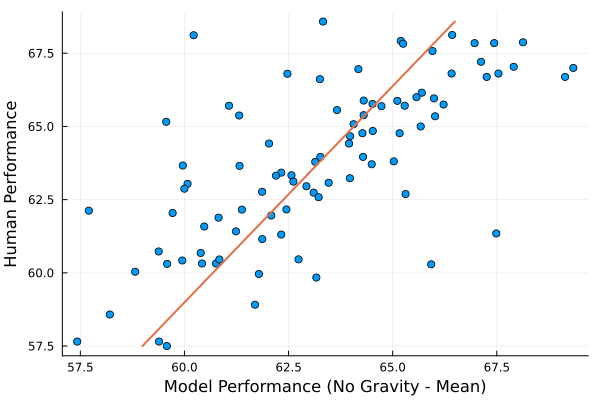

No Gravity (Mean) | R = 0.6909476138411658, R² = 0.4774086050728005, p = 4.819755189992664e-14


100.0%┣█████████████████████████████████████████████┫ 90/90 [00:34<00:00, 3it/s]
100.0%┣█████████████████████████████████████████████┫ 90/90 [00:34<00:00, 3it/s]


Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.690948
    95% confidence interval: (0.5647, 0.7856)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-13

Details:
    number of observations:          90
    number of conditional variables: 0
    t-statistic:                     8.96614
    degrees of freedom:              88
No Gravity (Rounded) | R = 0.6868339086013084, R² = 0.4717408180045507, p = 7.791747117108561e-14
Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.686834
    95% confidence interval: (0.5593, 0.7826)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-13

Details:
    number of observations:          90
    numb

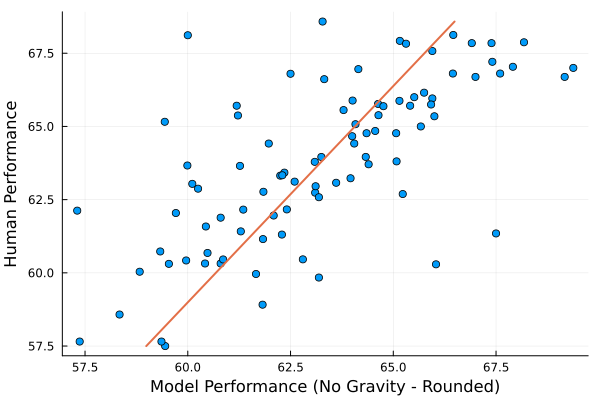

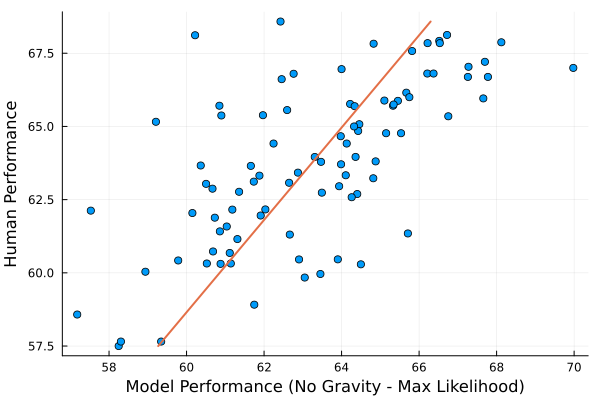

In [19]:
@gen function melody_kernel_no_grav(k::Int, state::Tuple{Note,Note}, key::MusicalScale, measure_length::Int=8)
    prev_note, curr_note = state

    Δt ~ categorical(fill(1.0 / measure_length, measure_length))

    magnetism = @trace(normal(calculate_magnetism(curr_note, key), σ_magnetism), :magnetism)
    inertia   = @trace(normal(calculate_inertia(prev_note, curr_note, key), σ_inertia), :inertia)

    base_force  = w_m*magnetism + w_i*inertia
    rhythm_scale = (Δt)^γ

    μ_step = α * rhythm_scale * base_force
    σ_step = σ_step_base * sqrt(Δt)

    step ~ normal(μ_step, σ_step)

    next_pitch = curr_note.value + step
    next_pos   = mod(curr_note.position - 1 + Δt, measure_length) + 1
    obs_pitch ~ normal(next_pitch, σ_pitch_obs)

    next_note = Note(next_pitch, next_pos)
    return (curr_note, next_note)
end

chain_no_grav = Gen.Unfold(melody_kernel_no_grav)

@gen function melody_no_grav(K::Int, key=nothing, init_notes=nothing)
    key = isnothing(key) ?
        @trace(draw(major_scales, fill(1 / length(major_scales), length(major_scales))), :key) :
        key

    init_state = isnothing(init_notes) ? error("init_notes required") : init_notes

    states ~ chain_no_grav(K - 2, init_state, key)

    notes = Note[init_state[1], init_state[2]]
    for st in states
        push!(notes, st[2])
    end
    return notes
end

function calculate_model_means_no_grav(
    melodies::Vector{Vector{Float64}},
    rhythms::Vector{Vector{Float64}},
    melody_keys::Vector{MusicalScale},
    n_particles::Int = 1000,
    horizon::Int = 100
)
    num_melodies = length(melodies)

    @assert length(rhythms) == num_melodies
    @assert length(melody_keys) == num_melodies

    mean_last_notes_all = Float64[]
    mean_rounded_last_notes_all = Float64[]
    highest_likelihood_notes_all = Float64[]
    sd_last_notes_all = Float64[]
    all_particles_all = Vector{Vector{Float64}}()

    for idx in ProgressBar(1:num_melodies)
        observed_notes   = melodies[idx]
        observed_rhythms = rhythms[idx]
        observed_key     = melody_keys[idx]

        @assert length(observed_notes) == length(observed_rhythms) """
        Melody / rhythm length mismatch at index $idx
        """

        obs_df = make_observations(observed_notes, observed_rhythms, observed_key)
        pf_traces = particle_filter(n_particles, horizon, observed_key, obs_df, melody_no_grav)

        last_notes = Float64[]
        for tr in pf_traces
            (_, last_note) = tr[:states][end]
            push!(last_notes, last_note.value)
        end

        mean_last_note         = mean(last_notes)
        mean_rounded_last_note = mean(round.(Int, last_notes))
        sd_last_note           = std(last_notes)

        # Highest-likelihood particle
        scores  = Gen.get_score.(pf_traces)
        best_i = argmax(scores)

        (_, best_last_note_obj) = pf_traces[best_i][:states][end]
        best_last_note = best_last_note_obj.value

        push!(mean_last_notes_all, mean_last_note)
        push!(mean_rounded_last_notes_all, mean_rounded_last_note)
        push!(highest_likelihood_notes_all, best_last_note)
        push!(sd_last_notes_all, sd_last_note)
        push!(all_particles_all, last_notes)
    end

    return mean_last_notes_all,
           mean_rounded_last_notes_all,
           highest_likelihood_notes_all,
           sd_last_notes_all,
           all_particles_all
end

ab1_means, ab1_rounded_means, ab1_max_likelihood, ab1_sds, ab1_particles = calculate_model_means_no_grav(melodies, rhythms, melody_keys)

# Mean predictions
r_mean = cor(human_means, ab1_means)
ctest1 = CorrelationTest(human_means, ab1_means)
p_mean = pvalue(ctest1)
viz1 = scatter(ab1_means, human_means, xlabel="Model Performance (No Gravity - Mean)", ylabel="Human Performance", legend=false)
line1 = lm(@formula(Y~x), DataFrame(Y=ab1_means, x=human_means))
rsq1 = r2(line1)
x_vals = range(minimum(human_means), maximum(human_means), length=100)
y_vals = predict(line1, DataFrame(x=x_vals))
display(plot!(viz1, y_vals, x_vals, linewidth=2))
println("No Gravity (Mean) | R = $r_mean, R² = $rsq1, p = $p_mean")
print(ctest1)

# Rounded mean predictions
r_rounded = cor(human_means, ab1_rounded_means)
ctest2 = CorrelationTest(human_means, ab1_rounded_means)
p_rounded = pvalue(ctest2)
viz2 = scatter(ab1_rounded_means, human_means, xlabel="Model Performance (No Gravity - Rounded)", ylabel="Human Performance", legend=false)
line2 = lm(@formula(Y~x), DataFrame(Y=ab1_rounded_means, x=human_means))
rsq2 = r2(line2)
y_vals2 = predict(line2, DataFrame(x=x_vals))
display(plot!(viz2, y_vals2, x_vals, linewidth=2))
println("No Gravity (Rounded) | R = $r_rounded, R² = $rsq2, p = $p_rounded")
print(ctest2)

# Max likelihood predictions
r_maxlik = cor(human_means, ab1_max_likelihood)
ctest3 = CorrelationTest(human_means, ab1_max_likelihood)
p_maxlik = pvalue(ctest3)
viz3 = scatter(ab1_max_likelihood, human_means, xlabel="Model Performance (No Gravity - Max Likelihood)", ylabel="Human Performance", legend=false)
line3 = lm(@formula(Y~x), DataFrame(Y=ab1_max_likelihood, x=human_means))
rsq3 = r2(line3)
y_vals3 = predict(line3, DataFrame(x=x_vals))
display(plot!(viz3, y_vals3, x_vals, linewidth=2))
println("No Gravity (Max Likelihood) | R = $r_maxlik, R² = $rsq3, p = $p_maxlik")
print(ctest3)

# Save to CSV
df_ab1 = DataFrame(
    IDs = stemIDs,
    human_means = human_means,
    model_means = ab1_means,
    rounded_means = ab1_rounded_means,
    max_likelihood = ab1_max_likelihood,
    sds = ab1_sds
)
CSV.write("exports/correlation_ab1.csv", df_ab1)

println("\nMean SD: ", mean(ab1_sds))
println("SD range: [", minimum(ab1_sds), ", ", maximum(ab1_sds), "]")

### No magnetism

0.0%┣                                               ┫ 0/90 [00:00<00:00, -0s/it]
1.1%┣▌                                          ┫ 1/90 [00:00<Inf:Inf, InfGs/it]
2.2%┣█                                               ┫ 2/90 [00:01<00:48, 2it/s]
3.3%┣█▋                                              ┫ 3/90 [00:01<00:29, 3it/s]
4.4%┣██▏                                             ┫ 4/90 [00:01<00:24, 4it/s]
5.6%┣██▊                                             ┫ 5/90 [00:01<00:21, 4it/s]
6.7%┣███▏                                            ┫ 6/90 [00:01<00:20, 4it/s]
7.8%┣███▊                                            ┫ 7/90 [00:01<00:20, 4it/s]
8.9%┣████▎                                           ┫ 8/90 [00:02<00:20, 4it/s]
10.0%┣████▊                                          ┫ 9/90 [00:02<00:20, 4it/s]
11.1%┣█████                                         ┫ 10/90 [00:02<00:21, 4it/s]
12.2%┣█████▋                                        ┫ 11/90 [00:03<00:21, 4it/s]
13.3%┣██████▏               

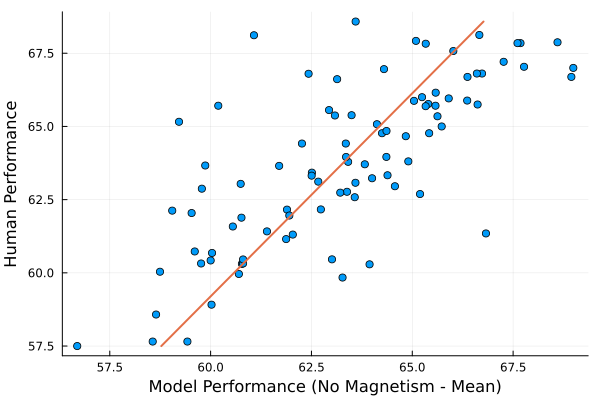

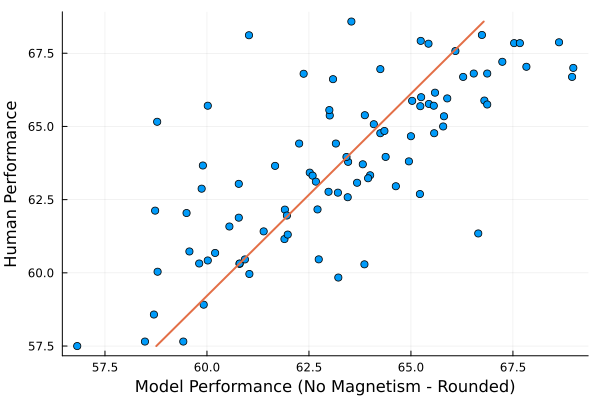

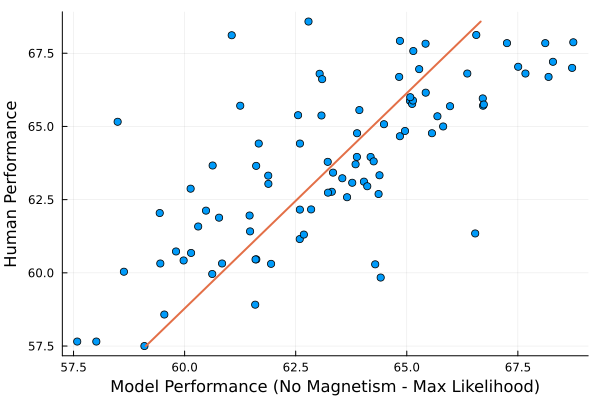

No Magnetism (Mean) | R = 0.7354346892586547, R² = 0.5408641821649736, p = 1.5251983371497257e-16
Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.735435
    95% confidence interval: (0.6233, 0.818)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-15

Details:
    number of observations:          90
    number of conditional variables: 0
    t-statistic:                     10.1816
    degrees of freedom:              88
No Magnetism (Rounded) | R = 0.7333662869350179, R² = 0.537826110812855, p = 2.0442193338326308e-16
Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.733366
    95% confidence interval: (0.6205, 0.8165)

Test summary:
    outcome with 95% confidence: reject h_0

100.0%┣█████████████████████████████████████████████┫ 90/90 [00:25<00:00, 4it/s]
100.0%┣█████████████████████████████████████████████┫ 90/90 [00:25<00:00, 4it/s]


Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.716515
    95% confidence interval: (0.5982, 0.8043)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-14

Details:
    number of observations:          90
    number of conditional variables: 0
    t-statistic:                     9.63558
    degrees of freedom:              88

Mean SD: 1.0389703465825708
SD range: [0.0, 1.8034362619240614]


In [20]:
@gen function melody_kernel_no_mag(k::Int, state::Tuple{Note,Note}, key::MusicalScale, measure_length::Int=8)
    prev_note, curr_note = state

    Δt ~ categorical(fill(1.0 / measure_length, measure_length))

    gravity = @trace(normal(calculate_gravity(curr_note, key), σ_gravity), :gravity)
    inertia = @trace(normal(calculate_inertia(prev_note, curr_note, key), σ_inertia), :inertia)

    base_force   = w_g*gravity + w_i*inertia
    rhythm_scale = (Δt)^γ

    μ_step = α * rhythm_scale * base_force
    σ_step = σ_step_base * sqrt(Δt)

    step ~ normal(μ_step, σ_step)

    next_pitch = curr_note.value + step
    next_pos   = mod(curr_note.position - 1 + Δt, measure_length) + 1
    obs_pitch ~ normal(next_pitch, σ_pitch_obs)

    next_note = Note(next_pitch, next_pos)
    return (curr_note, next_note)
end

chain_no_mag = Gen.Unfold(melody_kernel_no_mag)

@gen function melody_no_mag(K::Int, key=nothing, init_notes=nothing)
    key = isnothing(key) ?
        @trace(draw(major_scales, fill(1 / length(major_scales), length(major_scales))), :key) :
        key

    init_state = isnothing(init_notes) ? error("init_notes required") : init_notes

    states ~ chain_no_mag(K - 2, init_state, key)

    notes = Note[init_state[1], init_state[2]]
    for st in states
        push!(notes, st[2])
    end
    return notes
end

function calculate_model_means_no_mag(
    melodies::Vector{Vector{Float64}},
    rhythms::Vector{Vector{Float64}},
    melody_keys::Vector{MusicalScale},
    n_particles::Int = 1000,
    horizon::Int = 100
)
    num_melodies = length(melodies)

    @assert length(rhythms) == num_melodies
    @assert length(melody_keys) == num_melodies

    mean_last_notes_all = Float64[]
    mean_rounded_last_notes_all = Float64[]
    highest_likelihood_notes_all = Float64[]
    sd_last_notes_all = Float64[]
    all_particles_all = Vector{Vector{Float64}}()

    for idx in ProgressBar(1:num_melodies)
        observed_notes   = melodies[idx]
        observed_rhythms = rhythms[idx]
        observed_key     = melody_keys[idx]

        @assert length(observed_notes) == length(observed_rhythms) """
        Melody / rhythm length mismatch at index $idx
        """

        obs_df = make_observations(observed_notes, observed_rhythms, observed_key)
        pf_traces = particle_filter(n_particles, horizon, observed_key, obs_df, melody_no_mag)

        last_notes = Float64[]
        for tr in pf_traces
            (_, last_note) = tr[:states][end]
            push!(last_notes, last_note.value)
        end

        mean_last_note         = mean(last_notes)
        mean_rounded_last_note = mean(round.(Int, last_notes))
        sd_last_note           = std(last_notes)

        # Highest-likelihood particle
        scores  = Gen.get_score.(pf_traces)
        best_i = argmax(scores)

        (_, best_last_note_obj) = pf_traces[best_i][:states][end]
        best_last_note = best_last_note_obj.value

        push!(mean_last_notes_all, mean_last_note)
        push!(mean_rounded_last_notes_all, mean_rounded_last_note)
        push!(highest_likelihood_notes_all, best_last_note)
        push!(sd_last_notes_all, sd_last_note)
        push!(all_particles_all, last_notes)
    end

    return mean_last_notes_all,
           mean_rounded_last_notes_all,
           highest_likelihood_notes_all,
           sd_last_notes_all,
           all_particles_all
end

ab2_means, ab2_rounded_means, ab2_max_likelihood, ab2_sds, ab2_particles = calculate_model_means_no_mag(melodies, rhythms, melody_keys)

# Mean predictions
r_mean = cor(human_means, ab2_means)
ctest1 = CorrelationTest(human_means, ab2_means)
p_mean = pvalue(ctest1)
viz1 = scatter(ab2_means, human_means, xlabel="Model Performance (No Magnetism - Mean)", ylabel="Human Performance", legend=false)
line1 = lm(@formula(Y~x), DataFrame(Y=ab2_means, x=human_means))
rsq1 = r2(line1)
x_vals = range(minimum(human_means), maximum(human_means), length=100)
y_vals = predict(line1, DataFrame(x=x_vals))
display(plot!(viz1, y_vals, x_vals, linewidth=2))
println("No Magnetism (Mean) | R = $r_mean, R² = $rsq1, p = $p_mean")
print(ctest1)

# Rounded mean predictions
r_rounded = cor(human_means, ab2_rounded_means)
ctest2 = CorrelationTest(human_means, ab2_rounded_means)
p_rounded = pvalue(ctest2)
viz2 = scatter(ab2_rounded_means, human_means, xlabel="Model Performance (No Magnetism - Rounded)", ylabel="Human Performance", legend=false)
line2 = lm(@formula(Y~x), DataFrame(Y=ab2_rounded_means, x=human_means))
rsq2 = r2(line2)
y_vals2 = predict(line2, DataFrame(x=x_vals))
display(plot!(viz2, y_vals2, x_vals, linewidth=2))
println("No Magnetism (Rounded) | R = $r_rounded, R² = $rsq2, p = $p_rounded")
print(ctest2)

# Max likelihood predictions
r_maxlik = cor(human_means, ab2_max_likelihood)
ctest3 = CorrelationTest(human_means, ab2_max_likelihood)
p_maxlik = pvalue(ctest3)
viz3 = scatter(ab2_max_likelihood, human_means, xlabel="Model Performance (No Magnetism - Max Likelihood)", ylabel="Human Performance", legend=false)
line3 = lm(@formula(Y~x), DataFrame(Y=ab2_max_likelihood, x=human_means))
rsq3 = r2(line3)
y_vals3 = predict(line3, DataFrame(x=x_vals))
display(plot!(viz3, y_vals3, x_vals, linewidth=2))
println("No Magnetism (Max Likelihood) | R = $r_maxlik, R² = $rsq3, p = $p_maxlik")
print(ctest3)

# Save to CSV
df_ab2 = DataFrame(
    IDs = stemIDs,
    human_means = human_means,
    model_means = ab2_means,
    rounded_means = ab2_rounded_means,
    max_likelihood = ab2_max_likelihood,
    sds = ab2_sds
)
CSV.write("exports/correlation_ab2.csv", df_ab2)

println("\nMean SD: ", mean(ab2_sds))
println("SD range: [", minimum(ab2_sds), ", ", maximum(ab2_sds), "]")

### No inertia

0.0%┣                                               ┫ 0/90 [00:00<00:00, -0s/it]
1.1%┣▌                                          ┫ 1/90 [00:00<Inf:Inf, InfGs/it]
2.2%┣█                                               ┫ 2/90 [00:01<00:59, 1it/s]
3.3%┣█▋                                              ┫ 3/90 [00:01<00:35, 2it/s]
4.4%┣██▏                                             ┫ 4/90 [00:01<00:28, 3it/s]
5.6%┣██▊                                             ┫ 5/90 [00:01<00:24, 3it/s]
6.7%┣███▏                                            ┫ 6/90 [00:01<00:23, 4it/s]
7.8%┣███▊                                            ┫ 7/90 [00:02<00:23, 4it/s]
8.9%┣████▎                                           ┫ 8/90 [00:02<00:23, 4it/s]
10.0%┣████▊                                          ┫ 9/90 [00:02<00:23, 4it/s]
11.1%┣█████                                         ┫ 10/90 [00:03<00:23, 3it/s]
12.2%┣█████▋                                        ┫ 11/90 [00:03<00:23, 3it/s]
13.3%┣██████▏               

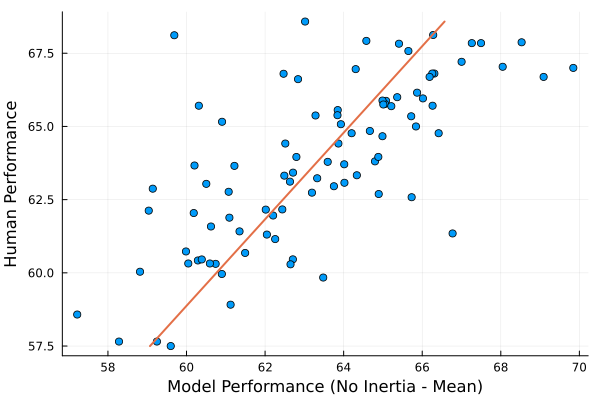

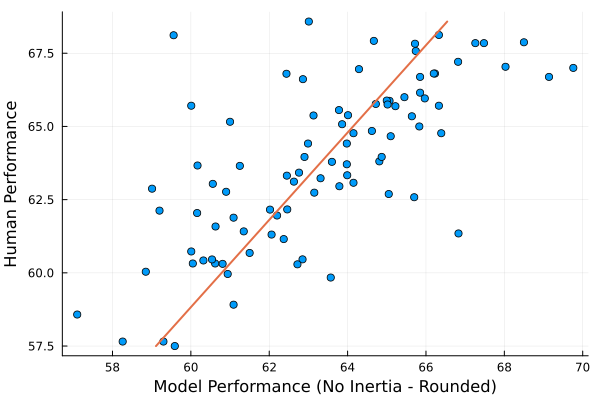

No Inertia (Mean) | R = 0.7072723070252974, R² = 0.5002341162848869, p = 6.605595113910624e-15
Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.707272
    95% confidence interval: (0.586, 0.7975)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-14

Details:
    number of observations:          90
    number of conditional variables: 0
    t-statistic:                     9.38522
    degrees of freedom:              88
No Inertia (Rounded) | R = 0.7022626224365486, R² = 0.49317279087145827, p = 1.2330306332230998e-14


100.0%┣█████████████████████████████████████████████┫ 90/90 [00:28<00:00, 3it/s]
100.0%┣█████████████████████████████████████████████┫ 90/90 [00:28<00:00, 3it/s]


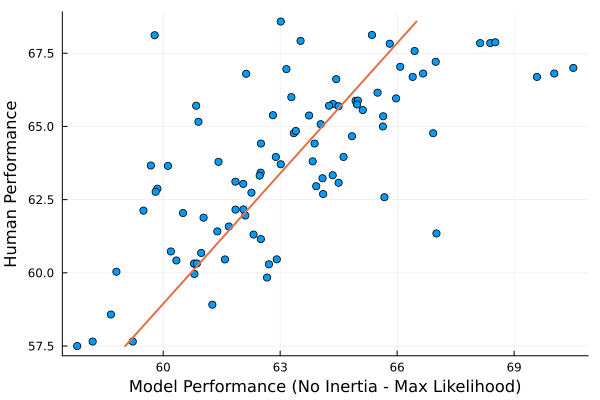

Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.702263
    95% confidence interval: (0.5794, 0.7939)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-13

Details:
    number of observations:          90
    number of conditional variables: 0
    t-statistic:                     9.2536
    degrees of freedom:              88
No Inertia (Max Likelihood) | R = 0.6893970849235577, R² = 0.47526834070109913, p = 5.781735676041792e-14
Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.689397
    95% confidence interval: (0.5626, 0.7845)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-13

Details:
    number of observations:          90
 

In [21]:
@gen function melody_kernel_no_in(k::Int, state::Tuple{Note,Note}, key::MusicalScale, measure_length::Int=8)
    prev_note, curr_note = state

    Δt ~ categorical(fill(1.0 / measure_length, measure_length))

    gravity   = @trace(normal(calculate_gravity(curr_note, key), σ_gravity), :gravity)
    magnetism = @trace(normal(calculate_magnetism(curr_note, key), σ_magnetism), :magnetism)

    base_force   = w_g*gravity + w_m*magnetism
    rhythm_scale = (Δt)^γ

    μ_step = α * rhythm_scale * base_force
    σ_step = σ_step_base * sqrt(Δt)

    step ~ normal(μ_step, σ_step)

    next_pitch = curr_note.value + step
    next_pos   = mod(curr_note.position - 1 + Δt, measure_length) + 1
    obs_pitch ~ normal(next_pitch, σ_pitch_obs)

    next_note = Note(next_pitch, next_pos)
    return (curr_note, next_note)
end

chain_no_in = Gen.Unfold(melody_kernel_no_in)

@gen function melody_no_in(K::Int, key=nothing, init_notes=nothing)
    key = isnothing(key) ?
        @trace(draw(major_scales, fill(1 / length(major_scales), length(major_scales))), :key) :
        key

    init_state = isnothing(init_notes) ? error("init_notes required") : init_notes

    states ~ chain_no_in(K - 2, init_state, key)

    notes = Note[init_state[1], init_state[2]]
    for st in states
        push!(notes, st[2])
    end
    return notes
end

function calculate_model_means_no_in(
    melodies::Vector{Vector{Float64}},
    rhythms::Vector{Vector{Float64}},
    melody_keys::Vector{MusicalScale},
    n_particles::Int = 1000,
    horizon::Int = 100
)
    num_melodies = length(melodies)

    @assert length(rhythms) == num_melodies
    @assert length(melody_keys) == num_melodies

    mean_last_notes_all = Float64[]
    mean_rounded_last_notes_all = Float64[]
    highest_likelihood_notes_all = Float64[]
    sd_last_notes_all = Float64[]
    all_particles_all = Vector{Vector{Float64}}()

    for idx in ProgressBar(1:num_melodies)
        observed_notes   = melodies[idx]
        observed_rhythms = rhythms[idx]
        observed_key     = melody_keys[idx]

        @assert length(observed_notes) == length(observed_rhythms) """
        Melody / rhythm length mismatch at index $idx
        """

        obs_df = make_observations(observed_notes, observed_rhythms, observed_key)
        pf_traces = particle_filter(n_particles, horizon, observed_key, obs_df, melody_no_in)

        last_notes = Float64[]
        for tr in pf_traces
            (_, last_note) = tr[:states][end]
            push!(last_notes, last_note.value)
        end

        mean_last_note         = mean(last_notes)
        mean_rounded_last_note = mean(round.(Int, last_notes))
        sd_last_note           = std(last_notes)

        # Highest-likelihood particle
        scores  = Gen.get_score.(pf_traces)
        best_i = argmax(scores)

        (_, best_last_note_obj) = pf_traces[best_i][:states][end]
        best_last_note = best_last_note_obj.value

        push!(mean_last_notes_all, mean_last_note)
        push!(mean_rounded_last_notes_all, mean_rounded_last_note)
        push!(highest_likelihood_notes_all, best_last_note)
        push!(sd_last_notes_all, sd_last_note)
        push!(all_particles_all, last_notes)
    end

    return mean_last_notes_all,
           mean_rounded_last_notes_all,
           highest_likelihood_notes_all,
           sd_last_notes_all,
           all_particles_all
end

ab3_means, ab3_rounded_means, ab3_max_likelihood, ab3_sds, ab3_particles = calculate_model_means_no_in(melodies, rhythms, melody_keys)

# Mean predictions
r_mean = cor(human_means, ab3_means)
ctest1 = CorrelationTest(human_means, ab3_means)
p_mean = pvalue(ctest1)
viz1 = scatter(ab3_means, human_means, xlabel="Model Performance (No Inertia - Mean)", ylabel="Human Performance", legend=false)
line1 = lm(@formula(Y~x), DataFrame(Y=ab3_means, x=human_means))
rsq1 = r2(line1)
x_vals = range(minimum(human_means), maximum(human_means), length=100)
y_vals = predict(line1, DataFrame(x=x_vals))
display(plot!(viz1, y_vals, x_vals, linewidth=2))
println("No Inertia (Mean) | R = $r_mean, R² = $rsq1, p = $p_mean")
print(ctest1)

# Rounded mean predictions
r_rounded = cor(human_means, ab3_rounded_means)
ctest2 = CorrelationTest(human_means, ab3_rounded_means)
p_rounded = pvalue(ctest2)
viz2 = scatter(ab3_rounded_means, human_means, xlabel="Model Performance (No Inertia - Rounded)", ylabel="Human Performance", legend=false)
line2 = lm(@formula(Y~x), DataFrame(Y=ab3_rounded_means, x=human_means))
rsq2 = r2(line2)
y_vals2 = predict(line2, DataFrame(x=x_vals))
display(plot!(viz2, y_vals2, x_vals, linewidth=2))
println("No Inertia (Rounded) | R = $r_rounded, R² = $rsq2, p = $p_rounded")
print(ctest2)

# Max likelihood predictions
r_maxlik = cor(human_means, ab3_max_likelihood)
ctest3 = CorrelationTest(human_means, ab3_max_likelihood)
p_maxlik = pvalue(ctest3)
viz3 = scatter(ab3_max_likelihood, human_means, xlabel="Model Performance (No Inertia - Max Likelihood)", ylabel="Human Performance", legend=false)
line3 = lm(@formula(Y~x), DataFrame(Y=ab3_max_likelihood, x=human_means))
rsq3 = r2(line3)
y_vals3 = predict(line3, DataFrame(x=x_vals))
display(plot!(viz3, y_vals3, x_vals, linewidth=2))
println("No Inertia (Max Likelihood) | R = $r_maxlik, R² = $rsq3, p = $p_maxlik")
print(ctest3)

# Save to CSV
df_ab3 = DataFrame(
    IDs = stemIDs,
    human_means = human_means,
    model_means = ab3_means,
    rounded_means = ab3_rounded_means,
    max_likelihood = ab3_max_likelihood,
    sds = ab3_sds
)
CSV.write("exports/correlation_ab3.csv", df_ab3)

println("\nMean SD: ", mean(ab3_sds))
println("SD range: [", minimum(ab3_sds), ", ", maximum(ab3_sds), "]")

### Likelihood Analyses

In [25]:
N_REPS = 10

target_notes = human_means

results_full = (stem=Float64[], pred=Float64[], total=Float64[],
                cor_mean=Float64[], cor_rounded_mean=Float64[], cor_max=Float64[], cor_rounded_max=Float64[])

results_ablation = Dict(
    :no_grav => (stem=Float64[], pred=Float64[], total=Float64[],
                 cor_mean=Float64[], cor_rounded_mean=Float64[], cor_max=Float64[], cor_rounded_max=Float64[]),
    :no_mag  => (stem=Float64[], pred=Float64[], total=Float64[],
                 cor_mean=Float64[], cor_rounded_mean=Float64[], cor_max=Float64[], cor_rounded_max=Float64[]),
    :no_in   => (stem=Float64[], pred=Float64[], total=Float64[],
                 cor_mean=Float64[], cor_rounded_mean=Float64[], cor_max=Float64[], cor_rounded_max=Float64[])
)

for rep in 1:N_REPS
    println("Rep $rep / $N_REPS")

    f_stem, f_pred, f_total, f_cm, f_crm, f_cx, f_crx = calculate_all_lls(melodies, rhythms, melody_keys, target_notes; model=melody)
    push!(results_full.stem, mean(f_stem)); push!(results_full.pred, mean(f_pred)); push!(results_full.total, mean(f_total))
    push!(results_full.cor_mean, f_cm); push!(results_full.cor_rounded_mean, f_crm)
    push!(results_full.cor_max, f_cx); push!(results_full.cor_rounded_max, f_crx)

    ng_stem, ng_pred, ng_total, ng_cm, ng_crm, ng_cx, ng_crx = calculate_all_lls(melodies, rhythms, melody_keys, target_notes; model=melody_no_grav)
    push!(results_ablation[:no_grav].stem, mean(ng_stem)); push!(results_ablation[:no_grav].pred, mean(ng_pred)); push!(results_ablation[:no_grav].total, mean(ng_total))
    push!(results_ablation[:no_grav].cor_mean, ng_cm); push!(results_ablation[:no_grav].cor_rounded_mean, ng_crm)
    push!(results_ablation[:no_grav].cor_max, ng_cx); push!(results_ablation[:no_grav].cor_rounded_max, ng_crx)

    nm_stem, nm_pred, nm_total, nm_cm, nm_crm, nm_cx, nm_crx = calculate_all_lls(melodies, rhythms, melody_keys, target_notes; model=melody_no_mag)
    push!(results_ablation[:no_mag].stem, mean(nm_stem)); push!(results_ablation[:no_mag].pred, mean(nm_pred)); push!(results_ablation[:no_mag].total, mean(nm_total))
    push!(results_ablation[:no_mag].cor_mean, nm_cm); push!(results_ablation[:no_mag].cor_rounded_mean, nm_crm)
    push!(results_ablation[:no_mag].cor_max, nm_cx); push!(results_ablation[:no_mag].cor_rounded_max, nm_crx)

    ni_stem, ni_pred, ni_total, ni_cm, ni_crm, ni_cx, ni_crx = calculate_all_lls(melodies, rhythms, melody_keys, target_notes; model=melody_no_in)
    push!(results_ablation[:no_in].stem, mean(ni_stem)); push!(results_ablation[:no_in].pred, mean(ni_pred)); push!(results_ablation[:no_in].total, mean(ni_total))
    push!(results_ablation[:no_in].cor_mean, ni_cm); push!(results_ablation[:no_in].cor_rounded_mean, ni_crm)
    push!(results_ablation[:no_in].cor_max, ni_cx); push!(results_ablation[:no_in].cor_rounded_max, ni_crx)
end

se(x) = std(x) / sqrt(length(x))

println("\n=== Full model ===")
println("  Stem LL:          ", round(mean(results_full.stem),  digits=4), " ± ", round(se(results_full.stem),  digits=4))
println("  Pred note LL:     ", round(mean(results_full.pred),  digits=4), " ± ", round(se(results_full.pred),  digits=4))
println("  Total LL:         ", round(mean(results_full.total), digits=4), " ± ", round(se(results_full.total), digits=4))
println("  Cor (mean):       ", round(mean(results_full.cor_mean), digits=4), " ± ", round(se(results_full.cor_mean), digits=4))
println("  Cor (round mean): ", round(mean(results_full.cor_rounded_mean), digits=4), " ± ", round(se(results_full.cor_rounded_mean), digits=4))
println("  Cor (max):        ", round(mean(results_full.cor_max), digits=4), " ± ", round(se(results_full.cor_max), digits=4))
println("  Cor (round max):  ", round(mean(results_full.cor_rounded_max), digits=4), " ± ", round(se(results_full.cor_rounded_max), digits=4))

for (label, res) in results_ablation
    println("\n=== $label ===")
    println("  Stem LL:          ", round(mean(res.stem),  digits=4), " ± ", round(se(res.stem),  digits=4))
    println("  Pred note LL:     ", round(mean(res.pred),  digits=4), " ± ", round(se(res.pred),  digits=4))
    println("  Total LL:         ", round(mean(res.total), digits=4), " ± ", round(se(res.total), digits=4))
    println("  Cor (mean):       ", round(mean(res.cor_mean), digits=4), " ± ", round(se(res.cor_mean), digits=4))
    println("  Cor (round mean): ", round(mean(res.cor_rounded_mean), digits=4), " ± ", round(se(res.cor_rounded_mean), digits=4))
    println("  Cor (max):        ", round(mean(res.cor_max), digits=4), " ± ", round(se(res.cor_max), digits=4))
    println("  Cor (round max):  ", round(mean(res.cor_rounded_max), digits=4), " ± ", round(se(res.cor_rounded_max), digits=4))
end

ablation_df = DataFrame(
    model              = String[],
    rep                = Int[],
    mean_stem_ll       = Float64[],
    mean_pred_ll       = Float64[],
    mean_total_ll      = Float64[],
    cor_mean           = Float64[],
    cor_rounded_mean   = Float64[],
    cor_max            = Float64[],
    cor_rounded_max    = Float64[]
)
for (label, res) in results_ablation
    for i in 1:N_REPS
        push!(ablation_df, (string(label), i, res.stem[i], res.pred[i], res.total[i],
                            res.cor_mean[i], res.cor_rounded_mean[i], res.cor_max[i], res.cor_rounded_max[i]))
    end
end
for i in 1:N_REPS
    push!(ablation_df, ("full", i, results_full.stem[i], results_full.pred[i], results_full.total[i],
                        results_full.cor_mean[i], results_full.cor_rounded_mean[i], results_full.cor_max[i], results_full.cor_rounded_max[i]))
end
CSV.write("exports/ablation_lls.csv", ablation_df)

Rep 1 / 10


0.0%┣                                               ┫ 0/90 [00:00<00:00, -0s/it]
1.1%┣▌                                          ┫ 1/90 [00:01<Inf:Inf, InfGs/it]
2.2%┣█                                               ┫ 2/90 [00:01<01:39, 1s/it]
3.3%┣█▋                                              ┫ 3/90 [00:01<00:57, 2it/s]
4.4%┣██▏                                             ┫ 4/90 [00:01<00:42, 2it/s]
5.6%┣██▊                                             ┫ 5/90 [00:02<00:36, 2it/s]
6.7%┣███▏                                            ┫ 6/90 [00:02<00:33, 3it/s]
7.8%┣███▊                                            ┫ 7/90 [00:02<00:31, 3it/s]
8.9%┣████▎                                           ┫ 8/90 [00:03<00:30, 3it/s]
10.0%┣████▊                                          ┫ 9/90 [00:03<00:30, 3it/s]
11.1%┣█████                                         ┫ 10/90 [00:03<00:31, 3it/s]
12.2%┣█████▋                                        ┫ 11/90 [00:04<00:30, 3it/s]
13.3%┣██████▏               

"exports/ablation_lls.csv"

## Melody plots

In [35]:
function visualize_melody(obs_notes::Vector{Float64},
                          human_mean::Float64,
                          melody_name::String)

    obs_vals = [obs_notes; human_mean]
    n_obs = length(obs_vals)

    p = plot(
        1:n_obs,
        obs_vals,
        linewidth = 3,
        color = :navy,
        legend = false,
        xlabel = "Time Step",
        ylabel = "Pitch (MIDI)",
        title = melody_name,
        xtickfontsize = 16,
        ytickfontsize = 16,
        guidefontsize = 16,
        titlefontsize = 16
    )

    display(p)
    return p
end
;

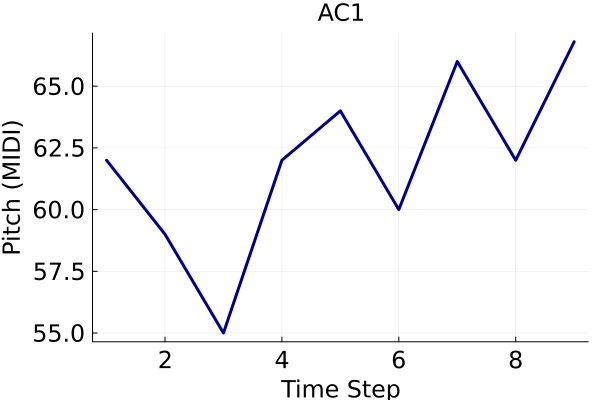

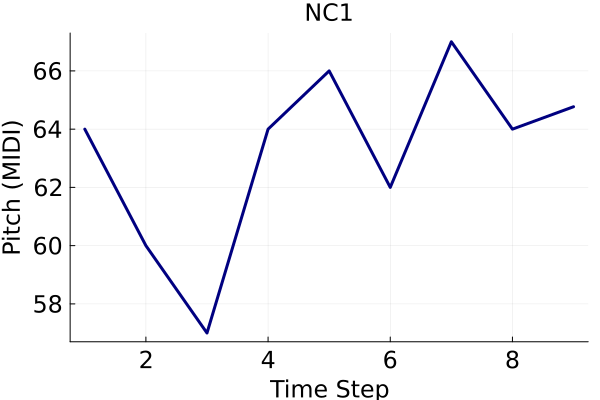

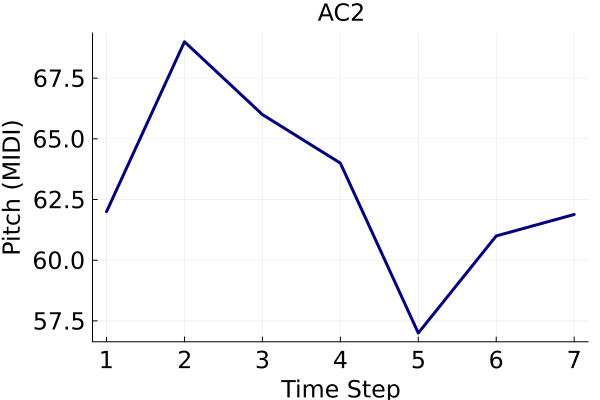

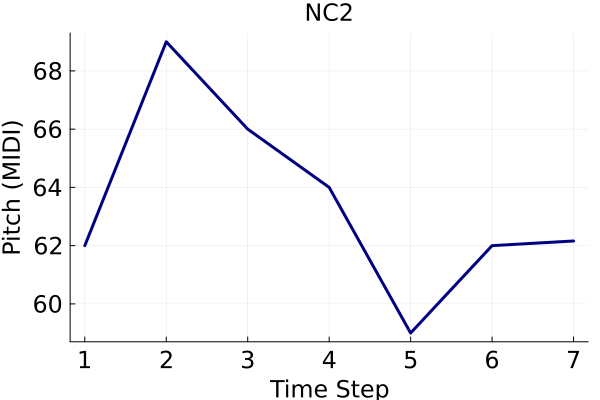

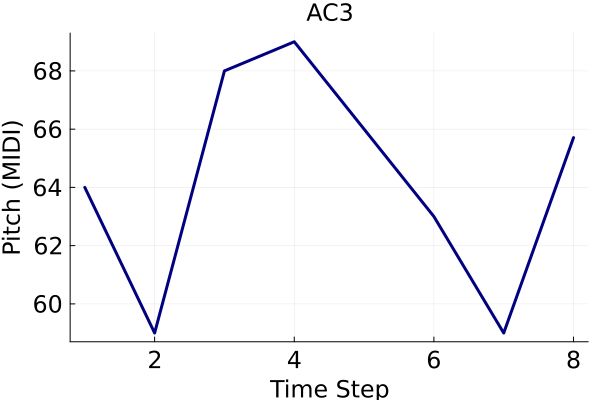

...

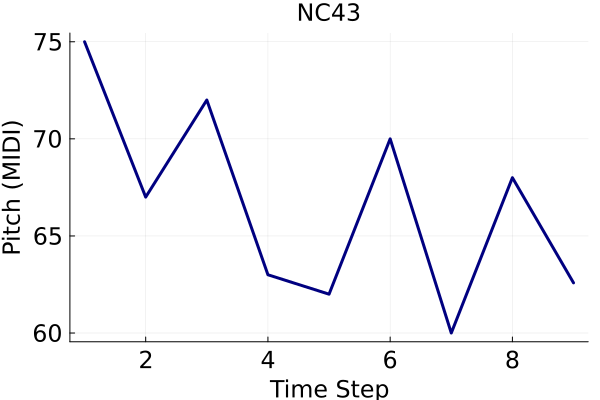

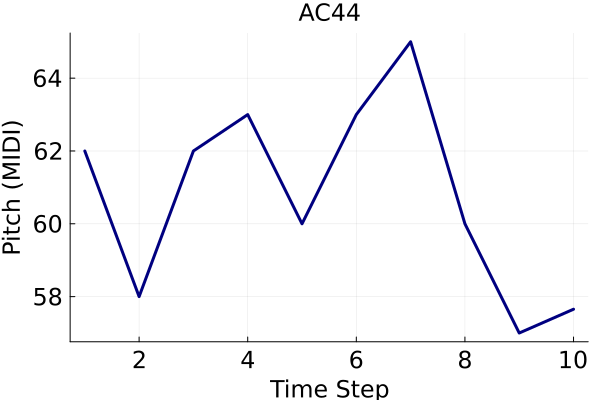

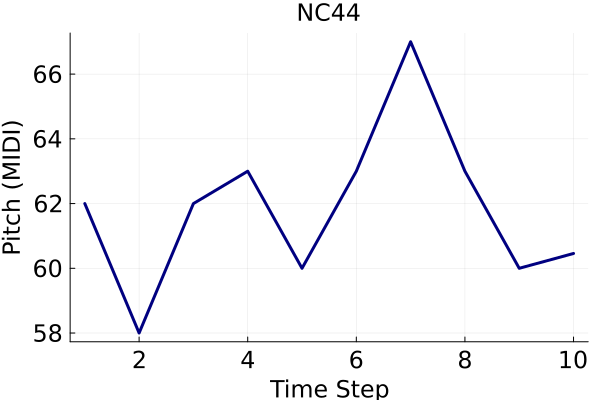

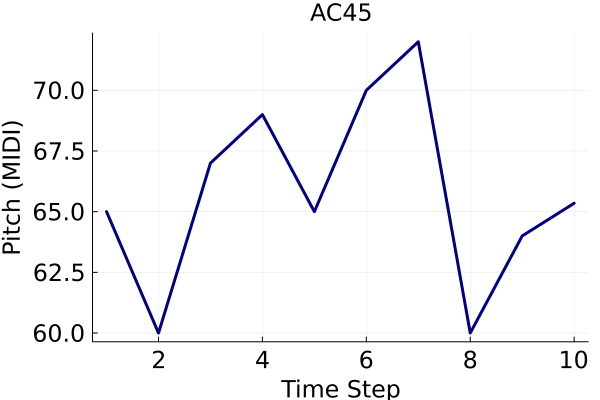

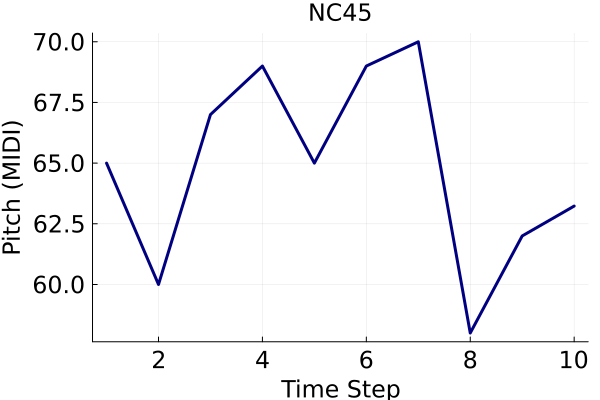

In [36]:
for i in 1:length(melodies)
    p = visualize_melody(melodies[i], human_means[i], stemIDs[i])
    savefig(p, "exports/melody_plots/$(stemIDs[i]).png")
end